# Análisis de rendimiento en League of Legends
## Jugador: KBTZASK8#9829 · Ranked Solo/Duo

**Para qué sirve este análisis:** entender qué hace ganar a este jugador, dónde falla y qué conviene que mantenga, usando sus últimas 100 partidas.

**Tres preguntas que responde:**
1. ¿Qué tiene de diferente una victoria frente a una derrota?
2. ¿Dónde y cuándo pierde partidas (muertes, arranque, duración, horario)?
3. ¿Qué debería mantener, corregir y probar?

**Cómo está organizado:** cada sección tiene una explicación corta, el código y al final una *lectura* automática con los números reales. Las conclusiones están en la sección 14.

> **Importante:** son ~90 partidas, así que los resultados son **tendencias**, no certezas. Y una correlación no prueba una causa.

## 1. Configuración
Aquí se cambia lo único que puede variar entre ejecuciones. **La API key nunca se escribe en el código:** se guarda en los *Secretos* de Colab (ícono de llave) con el nombre `RIOT_API_KEY`.

In [ ]:
# 1. CONFIGURACIÓN (lo único que hay que tocar)

USAR_API = False          # True: descarga datos nuevos de Riot (necesita API key vigente)
                          # False: lee los CSV ya guardados (recomendado para exponer)

GAME_NAME = "KBTZASK8"
TAG_LINE  = "9829"
REGION    = "americas"    # LAN/LAS/NA/BR
COLA      = 420           # 420 = Ranked Solo/Duo
CANTIDAD  = 100           # partidas a pedir a Riot (máximo 100)

ZONA_HORARIA = "America/Bogota"   # zona del jugador (Riot guarda la hora en UTC)
MIN_PARTIDAS_CAMPEON = 3          # mínimo de partidas para mostrar un campeón

RUTA_MATCHES = "matches_2026.csv"
RUTA_FRAMES  = "frames_por_minuto.csv"
RUTA_EVENTOS = "eventos.csv"

In [ ]:
# Librerías y estilo general

import os, io, time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
import matplotlib.image as mpimg
from IPython.display import display

try:
    from google.colab import files, userdata
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:.2f}")

# Colores usados en todo el notebook (verde = bueno, rojo = malo)
VERDE, ROJO, AZUL, NARANJA, GRIS = "#2E9E6B", "#D9534F", "#2E86AB", "#E9A23B", "#6B7A90"
COLOR_RESULTADO = {"Victoria": AZUL, "Derrota": "#E4572E"}

os.makedirs("graficos", exist_ok=True)

def guardar_fig(fig, nombre):
    """Guarda la gráfica como imagen en alta calidad para las diapositivas."""
    fig.savefig(f"graficos/{nombre}.png", dpi=200, bbox_inches="tight", facecolor="white")

## 2. Obtención de datos (API de Riot)
Esta celda solo **define** las funciones; no llama a Riot hasta que `USAR_API = True`. Así el notebook funciona el día de la exposición aunque la API falle.

In [ ]:
# 2. FUNCIONES PARA LA API DE RIOT

def riot_get(url, params=None, reintentos=5):
    """GET con manejo de límite de llamadas (429) y errores temporales."""
    for intento in range(reintentos):
        r = requests.get(url, headers=HEADERS, params=params, timeout=20)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429:
            espera = int(r.headers.get("Retry-After", 5)) + 1
            print(f"  Límite de llamadas, esperando {espera}s...")
            time.sleep(espera)
            continue
        if r.status_code >= 500:
            time.sleep(2 * (intento + 1))
            continue
        if r.status_code in (401, 403):
            raise RuntimeError("API key inválida o vencida. Genera una nueva en developer.riotgames.com")
        r.raise_for_status()
    raise RuntimeError(f"No se pudo obtener {url}")

def obtener_puuid(nombre, tag):
    return riot_get(f"https://{REGION}.api.riotgames.com/riot/account/v1/accounts/by-riot-id/{nombre}/{tag}")["puuid"]

def obtener_ids_partidas(puuid, cantidad=100, cola=None):
    params = {"start": 0, "count": cantidad}
    if cola is not None:
        params["queue"] = cola
    return riot_get(f"https://{REGION}.api.riotgames.com/lol/match/v5/matches/by-puuid/{puuid}/ids", params)

def partida_a_fila(partida, puuid):
    """Resume una partida de Riot en una fila con las estadísticas del jugador."""
    info = partida["info"]
    p = next(x for x in info["participants"] if x["puuid"] == puuid)
    minutos = info["gameDuration"] / 60
    cs = p["totalMinionsKilled"] + p["neutralMinionsKilled"]
    fila = {
        "match_id": partida["metadata"]["matchId"],
        "fecha": pd.to_datetime(info["gameCreation"], unit="ms", utc=True).tz_convert(ZONA_HORARIA).tz_localize(None),  # hora local
        "duracion_minutos": round(minutos, 2),
        "queue_id": info["queueId"],
        "cola": {420: "Ranked Solo/Duo", 440: "Ranked Flex"}.get(info["queueId"], str(info["queueId"])),
        "remake": bool(p.get("gameEndedInEarlySurrender", False)) or info["gameDuration"] < 300,
        "equipo": "azul" if p["teamId"] == 100 else "rojo",
        "champion": p["championName"],
        "position": p.get("teamPosition", ""),
        "win": bool(p["win"]),
        "kills": p["kills"], "deaths": p["deaths"], "assists": p["assists"],
        "kda": round((p["kills"] + p["assists"]) / max(p["deaths"], 1), 2),
        "cs_por_min": round(cs / minutos, 2),
        "gold_earned": p["goldEarned"],
        "gold_por_min": round(p["goldEarned"] / minutos, 1),
        "champ_level": p["champLevel"],
        "damage_dealt": p["totalDamageDealtToChampions"],
        "damage_taken": p["totalDamageTaken"],
        "vision_score": p["visionScore"],
        "wards_placed": p["wardsPlaced"],
        "wards_killed": p["wardsKilled"],
    }
    return fila

TIPOS_EVENTO = {"CHAMPION_KILL", "ELITE_MONSTER_KILL", "BUILDING_KILL",
                "TURRET_PLATE_DESTROYED", "WARD_PLACED", "WARD_KILL"}

def descargar_timeline(match_id, puuid):
    """Devuelve (frames, eventos): una fila por jugador y minuto, y los eventos de la partida."""
    t = riot_get(f"https://{REGION}.api.riotgames.com/lol/match/v5/matches/{match_id}/timeline")
    mi_id = t["metadata"]["participants"].index(puuid) + 1
    frames, eventos = [], []
    for f in t["info"]["frames"]:
        minuto = round(f["timestamp"] / 60000, 2)
        for pid, pf in f["participantFrames"].items():
            pid = int(pid)
            dmg = pf.get("damageStats", {})
            frames.append({
                "match_id": match_id, "minuto": minuto, "participant_id": pid,
                "equipo": 100 if pid <= 5 else 200, "es_mi_jugador": pid == mi_id,
                "nivel": pf.get("level"), "xp": pf.get("xp"),
                "oro_total": pf.get("totalGold"), "oro_actual": pf.get("currentGold"),
                "cs_linea": pf.get("minionsKilled"), "cs_jungla": pf.get("jungleMinionsKilled"),
                "dano_a_campeones": dmg.get("totalDamageDoneToChampions"),
                "dano_recibido": dmg.get("totalDamageTaken"),
                "x": pf.get("position", {}).get("x"), "y": pf.get("position", {}).get("y"),
            })
        for e in f["events"]:
            if e["type"] in TIPOS_EVENTO:
                eventos.append({
                    "match_id": match_id, "minuto": round(e["timestamp"] / 60000, 2), "tipo": e["type"],
                    "participant_id": e.get("participantId"), "killer_id": e.get("killerId"),
                    "victim_id": e.get("victimId"),
                    "asistentes": ",".join(map(str, e.get("assistingParticipantIds", []))),
                    "es_mi_jugador": mi_id in (e.get("participantId"), e.get("killerId"), e.get("victimId")),
                    "monstruo": e.get("monsterType"), "edificio": e.get("buildingType"),
                    "ward": e.get("wardType"),
                    "x": e.get("position", {}).get("x"), "y": e.get("position", {}).get("y"),
                })
    return frames, eventos

In [ ]:
# 2.1 DESCARGA (solo se ejecuta si USAR_API = True)

if USAR_API:
    API_KEY = userdata.get("RIOT_API_KEY").strip()      # la key vive en los Secretos de Colab
    HEADERS = {"X-Riot-Token": API_KEY}

    puuid = obtener_puuid(GAME_NAME, TAG_LINE)
    ids = obtener_ids_partidas(puuid, CANTIDAD, COLA)
    print(f"Partidas encontradas: {len(ids)}")

    # Partidas (se vuelve a crear el CSV con las últimas CANTIDAD)
    filas = []
    for n, match_id in enumerate(ids, start=1):
        filas.append(partida_a_fila(riot_get(f"https://{REGION}.api.riotgames.com/lol/match/v5/matches/{match_id}"), puuid))
        if n % 10 == 0:
            print(f"  Partidas {n}/{len(ids)}")
        time.sleep(0.15)
    pd.DataFrame(filas).to_csv(RUTA_MATCHES, index=False)

    # Minuto a minuto: solo baja las partidas que todavía no están guardadas
    ya = set(pd.read_csv(RUTA_FRAMES, usecols=["match_id"])["match_id"]) if os.path.exists(RUTA_FRAMES) else set()
    for n, match_id in enumerate([m for m in ids if m not in ya], start=1):
        try:
            fr, ev = descargar_timeline(match_id, puuid)
            pd.DataFrame(fr).to_csv(RUTA_FRAMES, mode="a", header=not os.path.exists(RUTA_FRAMES), index=False)
            pd.DataFrame(ev).to_csv(RUTA_EVENTOS, mode="a", header=not os.path.exists(RUTA_EVENTOS), index=False)
        except Exception as e:
            print(f"  Error en {match_id}: {e}")
        time.sleep(0.15)
    print("Descarga terminada.")
else:
    print("Modo sin API: se usarán los CSV guardados.")

Modo sin API: se usarán los CSV guardados.


## 3. Carga de los CSV y comprobación
Los tres archivos deben ser **de la misma fecha**. Esta sección lo comprueba para evitar mezclar partidas de épocas distintas.

In [ ]:
# 3. CARGA DESDE CSV + COMPROBACIÓN DE COHERENCIA

faltan = [r for r in (RUTA_MATCHES, RUTA_FRAMES, RUTA_EVENTOS) if not os.path.exists(r)]
if faltan and EN_COLAB:
    print("Sube estos archivos:", faltan)
    files.upload()

datos = pd.read_csv(RUTA_MATCHES, parse_dates=["fecha"])
frames = pd.read_csv(RUTA_FRAMES)
eventos = pd.read_csv(RUTA_EVENTOS)

print(f"Partidas: {len(datos)} | Frames (minuto a minuto): {len(frames):,} | Eventos: {len(eventos):,}")
print(f"Periodo: {datos['fecha'].min():%d/%m/%Y} → {datos['fecha'].max():%d/%m/%Y}")

en_comun = set(datos["match_id"]) & set(frames["match_id"])
print(f"Partidas con datos minuto a minuto: {len(en_comun)} de {datos['match_id'].nunique()}")
if len(en_comun) < datos["match_id"].nunique() - 3:
    print("⚠ Los archivos parecen ser de fechas distintas. Vuelve a descargarlos juntos.")

Sube estos archivos: ['matches_2026.csv', 'frames_por_minuto.csv', 'eventos.csv']


Saving matches_2026.csv to matches_2026.csv
Saving frames_por_minuto.csv to frames_por_minuto.csv
Saving eventos.csv to eventos.csv
Partidas: 100 | Frames (minuto a minuto): 28,690 | Eventos: 39,018
Periodo: 01/09/2026 → 08/11/2026
Partidas con datos minuto a minuto: 99 de 100


## 4. Limpieza
Los **remakes** (partidas que se cancelan en los primeros minutos) no reflejan cómo juega, así que se quitan. El resto del análisis usa solo las *partidas válidas*, en orden cronológico.

In [ ]:
# 4. LIMPIEZA Y PREPARACIÓN

datos["resultado"] = np.where(datos["win"], "Victoria", "Derrota")

partidas_validas = (
    datos[~datos["remake"]]
    .sort_values("fecha")
    .reset_index(drop=True)
)

# Los datos minuto a minuto también se limitan a las partidas válidas
ids_validas = set(partidas_validas["match_id"])
frames = frames[frames["match_id"].isin(ids_validas)].copy()
eventos = eventos[eventos["match_id"].isin(ids_validas)].copy()

# Número de participante de MI jugador en cada partida (sirve para kills y muertes)
mi_id = (frames[frames["es_mi_jugador"]]
         .groupby("match_id")["participant_id"].first().rename("mi_id"))

print(f"Partidas totales: {len(datos)} | Remakes quitados: {int(datos['remake'].sum())} | Válidas: {len(partidas_validas)}")
print("Posición jugada:", partidas_validas["position"].value_counts().to_dict())

Partidas totales: 100 | Remakes quitados: 9 | Válidas: 91
Posición jugada: {'BOTTOM': 86, 'MIDDLE': 4, 'UTILITY': 1}


## 5. Resumen general
Una foto rápida: cuántas partidas son, cuánto gana y con qué campeones juega.

In [ ]:
# 5. INDICADORES GENERALES

n_validas = len(partidas_validas)
victorias = int(partidas_validas["win"].sum())
winrate_valido = partidas_validas["win"].mean()

print("RESUMEN GENERAL")
print("-" * 45)
print(f"Partidas válidas:  {n_validas}")
print(f"Victorias:         {victorias}   |   Derrotas: {n_validas - victorias}")
print(f"Winrate:           {winrate_valido:.1%}")
print(f"Duración promedio: {partidas_validas['duracion_minutos'].mean():.1f} min")
print(f"KDA promedio:      {partidas_validas['kda'].mean():.2f}")
print()
print("Campeones más jugados:")
display(partidas_validas["champion"].value_counts().head(6).to_frame("partidas"))

RESUMEN GENERAL
---------------------------------------------
Partidas válidas:  91
Victorias:         45   |   Derrotas: 46
Winrate:           49.5%
Duración promedio: 29.6 min
KDA promedio:      2.70

Campeones más jugados:


,partidas
champion,
Caitlyn,22
Twitch,20
Jinx,8
Tristana,8
Yunara,5
Jhin,5


## 6. Victoria vs. derrota
**Cómo leerla:** cada cuadro es una métrica con su propia escala (no compares barras de cuadros distintos). El porcentaje del título dice cuánto más alta fue esa métrica en las victorias.

**Ojo:** parte de la diferencia es *consecuencia* de ganar (si vas ganando es más fácil tener kills y oro), no solo causa.

,kills,assists,gold_por_min,damage_dealt,vision_score,champ_level
resultado,,,,,,
Victoria,9.38,8.44,470.90,26946.31,22.73,15.40
Derrota,5.39,5.20,398.47,20369.52,18.65,12.89


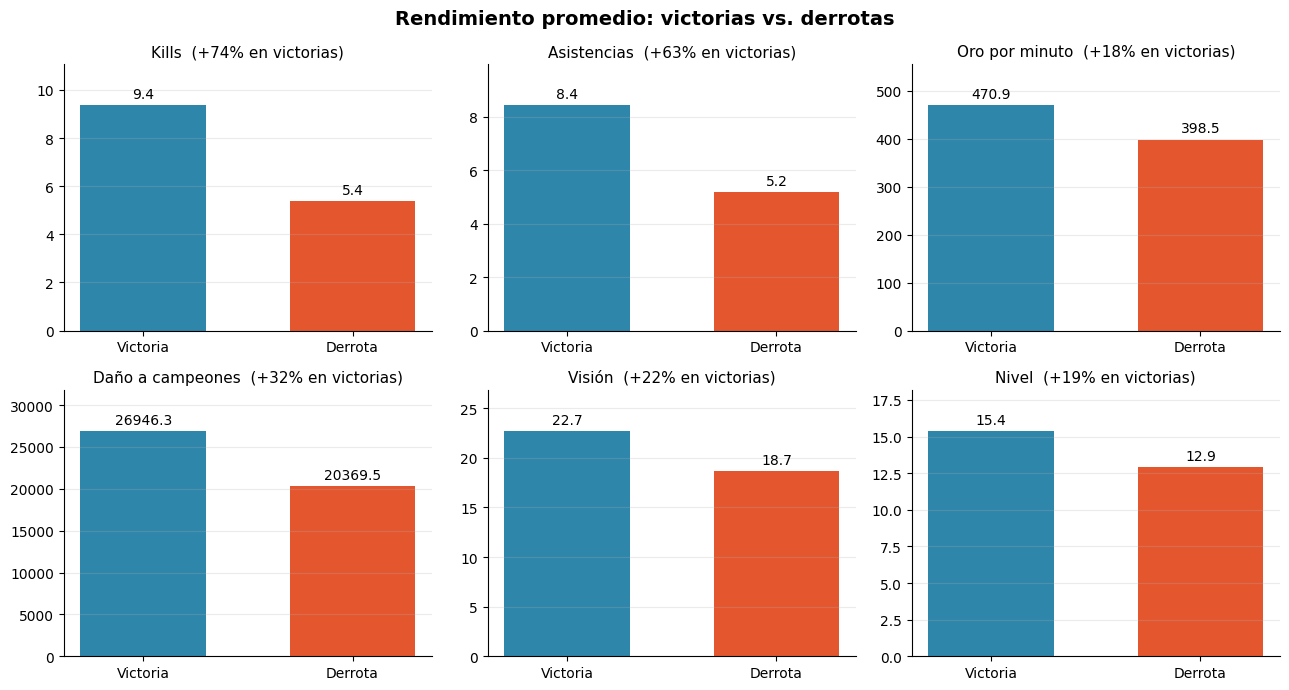

LECTURA
• Gana con 9.4 kills y 8.4 asistencias; pierde con 5.4 y 5.2.
• Sus victorias son partidas donde participa mucho en las peleas.


In [ ]:
# 6. GRÁFICO: VICTORIA VS. DERROTA

variables = ["kills", "assists", "gold_por_min", "damage_dealt", "vision_score", "champ_level"]
etiquetas = ["Kills", "Asistencias", "Oro por minuto", "Daño a campeones", "Visión", "Nivel"]

promedios = partidas_validas.groupby("resultado")[variables].mean().reindex(["Victoria", "Derrota"])
display(promedios.round(2))

fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
for eje, var, etiqueta in zip(ejes.flat, variables, etiquetas):
    valores = promedios[var]
    barras = eje.bar(valores.index, valores.values, color=[COLOR_RESULTADO[r] for r in valores.index], width=0.6)
    eje.bar_label(barras, fmt="%.1f", padding=3, fontsize=10)
    dif = (valores["Victoria"] / valores["Derrota"] - 1) * 100
    eje.set_title(f"{etiqueta}  ({dif:+.0f}% en victorias)", fontsize=11)
    eje.set_ylim(0, valores.max() * 1.18)
    eje.grid(axis="y", alpha=0.25)
    eje.spines[["top", "right"]].set_visible(False)
fig.suptitle("Rendimiento promedio: victorias vs. derrotas", fontsize=14, fontweight="bold")
plt.tight_layout()
guardar_fig(fig, "01_victoria_vs_derrota")
plt.show()

print("LECTURA")
print(f"• Gana con {promedios.loc['Victoria','kills']:.1f} kills y {promedios.loc['Victoria','assists']:.1f} asistencias; "
      f"pierde con {promedios.loc['Derrota','kills']:.1f} y {promedios.loc['Derrota','assists']:.1f}.")
print("• Sus victorias son partidas donde participa mucho en las peleas.")

## 7. Muertes
Este es el punto que más pesa en el diagnóstico. Se mira **cuántas muertes** tiene (no kills) y **en qué momento de la partida** muere.

**Cómo leer el gráfico de la derecha:** cada barra es el winrate cuando el jugador muere pocas, algunas o muchas veces. El número entre paréntesis son las partidas de ese grupo.

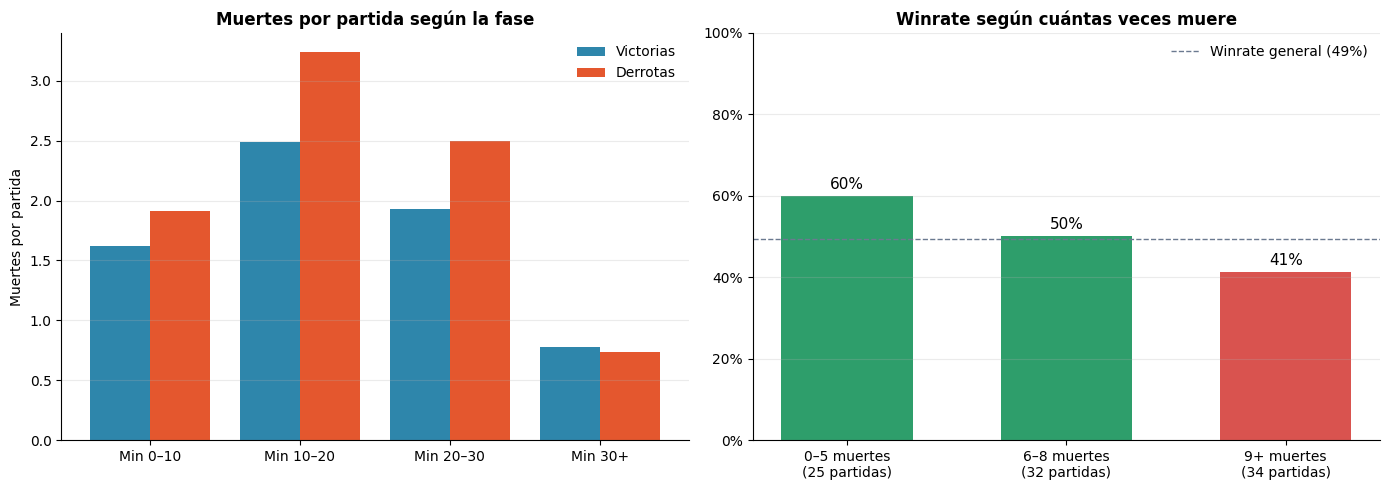

LECTURA
• Muere 7.7 veces por partida (6.9 al ganar, 8.5 al perder).
• La fase donde más muere es Min 10–20 (2.9 muertes por partida).
• Con 0–5 muertes gana el 60%; con 9 o más, el 41%.


In [ ]:
# 7. MUERTES POR FASE Y WINRATE SEGÚN MUERTES

# Muertes del jugador: eventos de kill donde la víctima soy yo
kills_ev = eventos[eventos["tipo"] == "CHAMPION_KILL"].join(mi_id, on="match_id")
mis_muertes = kills_ev[kills_ev["victim_id"] == kills_ev["mi_id"]].copy()
mis_muertes = mis_muertes.merge(partidas_validas[["match_id", "resultado"]], on="match_id")
mis_muertes["fase"] = pd.cut(mis_muertes["minuto"], [-1, 10, 20, 30, 999],
                             labels=["Min 0–10", "Min 10–20", "Min 20–30", "Min 30+"])

n_por_resultado = partidas_validas["resultado"].value_counts()
muertes_fase = (mis_muertes.groupby(["fase", "resultado"], observed=False).size().unstack(fill_value=0)
                .div(n_por_resultado, axis=1)[["Victoria", "Derrota"]])
muertes_promedio_fase = mis_muertes["fase"].value_counts().sort_index() / len(partidas_validas)

# Winrate según el número de muertes
grupos = pd.cut(partidas_validas["deaths"], [-1, 5, 8, 99], labels=["0–5 muertes", "6–8 muertes", "9+ muertes"])
wr_muertes = partidas_validas.groupby(grupos, observed=True)["win"].agg(["mean", "count"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(muertes_fase))
ax1.bar(x - 0.2, muertes_fase["Victoria"], 0.4, color=COLOR_RESULTADO["Victoria"], label="Victorias")
ax1.bar(x + 0.2, muertes_fase["Derrota"], 0.4, color=COLOR_RESULTADO["Derrota"], label="Derrotas")
ax1.set_xticks(x); ax1.set_xticklabels(muertes_fase.index)
ax1.set_title("Muertes por partida según la fase", fontweight="bold")
ax1.set_ylabel("Muertes por partida"); ax1.legend(frameon=False)
ax1.grid(axis="y", alpha=0.25); ax1.spines[["top", "right"]].set_visible(False)

colores = [VERDE if v >= 0.5 else ROJO for v in wr_muertes["mean"]]
barras = ax2.bar([f"{i}\n({int(n)} partidas)" for i, n in zip(wr_muertes.index, wr_muertes["count"])],
                 wr_muertes["mean"] * 100, color=colores, width=0.6)
ax2.bar_label(barras, labels=[f"{v:.0%}" for v in wr_muertes["mean"]], padding=3, fontsize=11)
ax2.axhline(winrate_valido * 100, color=GRIS, linestyle="--", linewidth=1, label=f"Winrate general ({winrate_valido:.0%})")
ax2.set_ylim(0, 100); ax2.yaxis.set_major_formatter(PercentFormatter(100))
ax2.set_title("Winrate según cuántas veces muere", fontweight="bold")
ax2.legend(frameon=False, loc="upper right")
ax2.grid(axis="y", alpha=0.25); ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "02_muertes")
plt.show()

fase_pico = muertes_promedio_fase.idxmax()
print("LECTURA")
print(f"• Muere {partidas_validas['deaths'].mean():.1f} veces por partida "
      f"({partidas_validas.loc[partidas_validas['win'], 'deaths'].mean():.1f} al ganar, "
      f"{partidas_validas.loc[~partidas_validas['win'], 'deaths'].mean():.1f} al perder).")
print(f"• La fase donde más muere es {fase_pico} ({muertes_promedio_fase.max():.1f} muertes por partida).")
print(f"• Con 0–5 muertes gana el {wr_muertes.loc['0–5 muertes','mean']:.0%}; con 9 o más, el {wr_muertes.loc['9+ muertes','mean']:.0%}.")

## 8. Fase de líneas: oro y CS frente a los rivales
Con los datos minuto a minuto se compara al jugador con el **promedio del equipo rival** en el minuto 10 y el 15.

**Cómo leerla:** a la izquierda, cuánto oro lleva de más (o de menos) respecto a los rivales. Si la barra es positiva va por delante. A la derecha, qué pasa con el winrate cuando va por delante o por detrás.

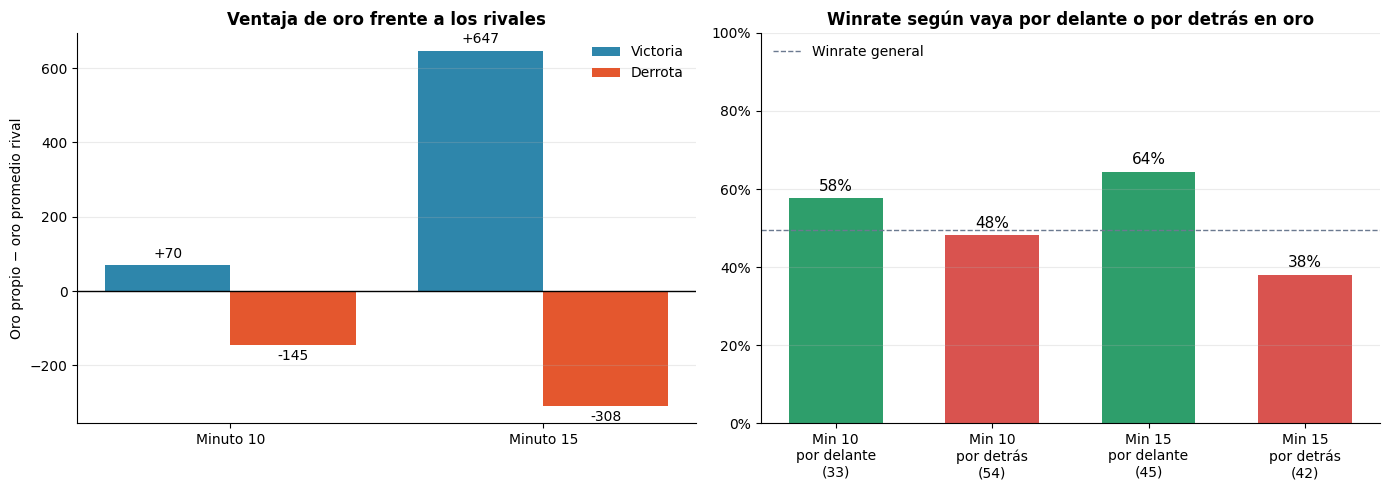

LECTURA
• Al minuto 15, en las derrotas va -308 de oro frente a los rivales; en las victorias, +647.
• Va por delante en oro al minuto 15 en el 52% de las partidas.


In [ ]:
# 8. VENTAJA DE ORO Y CS FRENTE A LOS RIVALES

def ventaja_en_minuto(minuto_objetivo):
    """Oro y CS del jugador menos el promedio del equipo rival, en ese minuto."""
    filas = []
    for match_id, d in frames.groupby("match_id"):
        tiempos = d["minuto"].unique()
        if tiempos.max() < minuto_objetivo:
            continue
        t = tiempos[np.abs(tiempos - minuto_objetivo).argmin()]   # el frame más cercano
        dd = d[d["minuto"] == t]
        yo = dd[dd["es_mi_jugador"]]
        if yo.empty:
            continue
        yo = yo.iloc[0]
        rivales = dd[dd["equipo"] != yo["equipo"]]
        filas.append({
            "match_id": match_id,
            "dif_oro": yo["oro_total"] - rivales["oro_total"].mean(),
            "dif_cs": (yo["cs_linea"] + yo["cs_jungla"]) - (rivales["cs_linea"] + rivales["cs_jungla"]).mean(),
        })
    return pd.DataFrame(filas).merge(partidas_validas[["match_id", "win", "resultado"]], on="match_id")

ventaja = {m: ventaja_en_minuto(m) for m in (10, 15)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Izquierda: diferencia de oro media según el resultado
x = np.arange(2)
for i, res in enumerate(["Victoria", "Derrota"]):
    vals = [ventaja[m][ventaja[m]["resultado"] == res]["dif_oro"].mean() for m in (10, 15)]
    b = ax1.bar(x + (i - 0.5) * 0.4, vals, 0.4, color=COLOR_RESULTADO[res], label=res)
    ax1.bar_label(b, fmt="%+.0f", padding=3, fontsize=10)
ax1.axhline(0, color="black", linewidth=1)
ax1.set_xticks(x); ax1.set_xticklabels(["Minuto 10", "Minuto 15"])
ax1.set_ylabel("Oro propio − oro promedio rival")
ax1.set_title("Ventaja de oro frente a los rivales", fontweight="bold")
ax1.legend(frameon=False); ax1.grid(axis="y", alpha=0.25); ax1.spines[["top", "right"]].set_visible(False)

# Derecha: winrate si va por delante o por detrás
etq, vals, cols, ns = [], [], [], []
for m in (10, 15):
    v = ventaja[m]
    for nombre, mascara, col in [("por delante", v["dif_oro"] > 0, VERDE), ("por detrás", v["dif_oro"] <= 0, ROJO)]:
        sub = v[mascara]
        etq.append(f"Min {m}\n{nombre}\n({len(sub)})"); vals.append(sub["win"].mean() * 100); cols.append(col)
barras = ax2.bar(etq, vals, color=cols, width=0.6)
ax2.bar_label(barras, fmt="%.0f%%", padding=3, fontsize=11)
ax2.axhline(winrate_valido * 100, color=GRIS, linestyle="--", linewidth=1, label="Winrate general")
ax2.set_ylim(0, 100); ax2.yaxis.set_major_formatter(PercentFormatter(100))
ax2.set_title("Winrate según vaya por delante o por detrás en oro", fontweight="bold")
ax2.legend(frameon=False, loc="upper left"); ax2.grid(axis="y", alpha=0.25); ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "03_oro_vs_rivales")
plt.show()

v15 = ventaja[15]
print("LECTURA")
print(f"• Al minuto 15, en las derrotas va {v15[v15['resultado']=='Derrota']['dif_oro'].mean():+.0f} de oro frente a los rivales; "
      f"en las victorias, {v15[v15['resultado']=='Victoria']['dif_oro'].mean():+.0f}.")
print(f"• Va por delante en oro al minuto 15 en el {(v15['dif_oro'] > 0).mean():.0%} de las partidas.")

## 9. Duración de las partidas
**Cómo leerla:** cada barra es el winrate según lo que dura la partida. Si las partidas cortas se pierden, normalmente el problema nació en la fase de líneas.

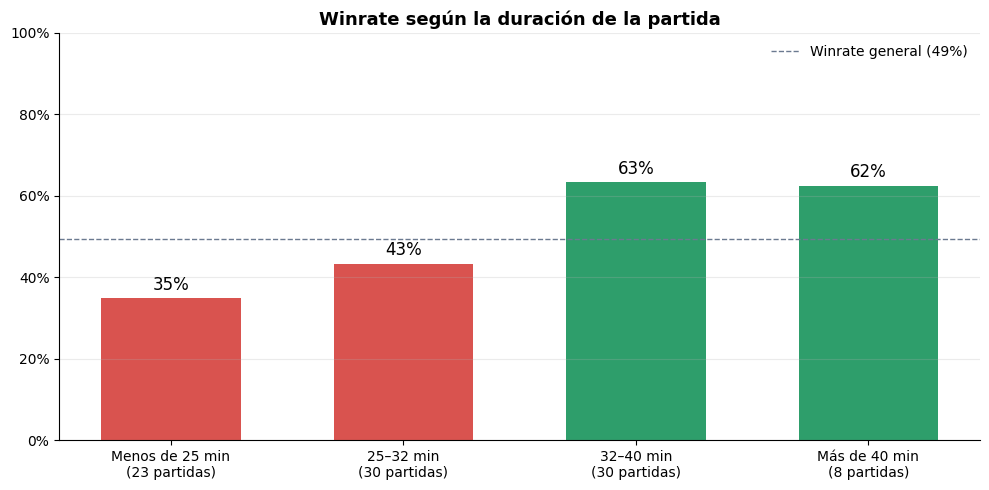

LECTURA
• Partidas de menos de 25 min: gana el 35%. De 32 a 40 min: 63%.


In [ ]:
# 9. WINRATE SEGÚN LA DURACIÓN

partidas_validas["duracion_grupo"] = pd.cut(partidas_validas["duracion_minutos"], [0, 25, 32, 40, 999],
                                            labels=["Menos de 25 min", "25–32 min", "32–40 min", "Más de 40 min"])
wr_duracion = partidas_validas.groupby("duracion_grupo", observed=True)["win"].agg(["mean", "count"])

fig, eje = plt.subplots(figsize=(10, 5))
barras = eje.bar([f"{i}\n({int(n)} partidas)" for i, n in zip(wr_duracion.index, wr_duracion["count"])],
                 wr_duracion["mean"] * 100, color=[VERDE if v >= 0.5 else ROJO for v in wr_duracion["mean"]], width=0.6)
eje.bar_label(barras, labels=[f"{v:.0%}" for v in wr_duracion["mean"]], padding=3, fontsize=12)
eje.axhline(winrate_valido * 100, color=GRIS, linestyle="--", linewidth=1, label=f"Winrate general ({winrate_valido:.0%})")
eje.set_ylim(0, 100); eje.yaxis.set_major_formatter(PercentFormatter(100))
eje.set_title("Winrate según la duración de la partida", fontsize=13, fontweight="bold")
eje.legend(frameon=False); eje.grid(axis="y", alpha=0.25); eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "04_duracion")
plt.show()

print("LECTURA")
print(f"• Partidas de menos de 25 min: gana el {wr_duracion.iloc[0]['mean']:.0%}. De 32 a 40 min: {wr_duracion.iloc[2]['mean']:.0%}.")

## 10. Campeones
**Cómo leerla:** cada barra es un campeón; verde si el winrate es 50% o más y rojo si es menor. Al lado de cada barra se muestra el récord (V = victorias, D = derrotas).

**Cuidado:** con pocas partidas un solo resultado mueve mucho el porcentaje. Los campeones con 3 o 4 partidas son solo una pista.

,champion,partidas,victorias,winrate,kda,muertes,cs_min
2,Caitlyn,22,14,0.64,2.91,7.18,6.40
13,Twitch,20,9,0.45,2.47,8.15,5.30
12,Tristana,8,4,0.50,2.24,6.62,6.43
6,Jinx,8,5,0.62,4.63,5.62,6.46
17,Yunara,5,1,0.20,1.43,8.80,6.11
5,Jhin,5,3,0.60,5.66,5.80,6.40
4,Ezreal,4,2,0.50,2.36,8.50,5.94
1,Ashe,3,1,0.33,1.55,10.67,5.73


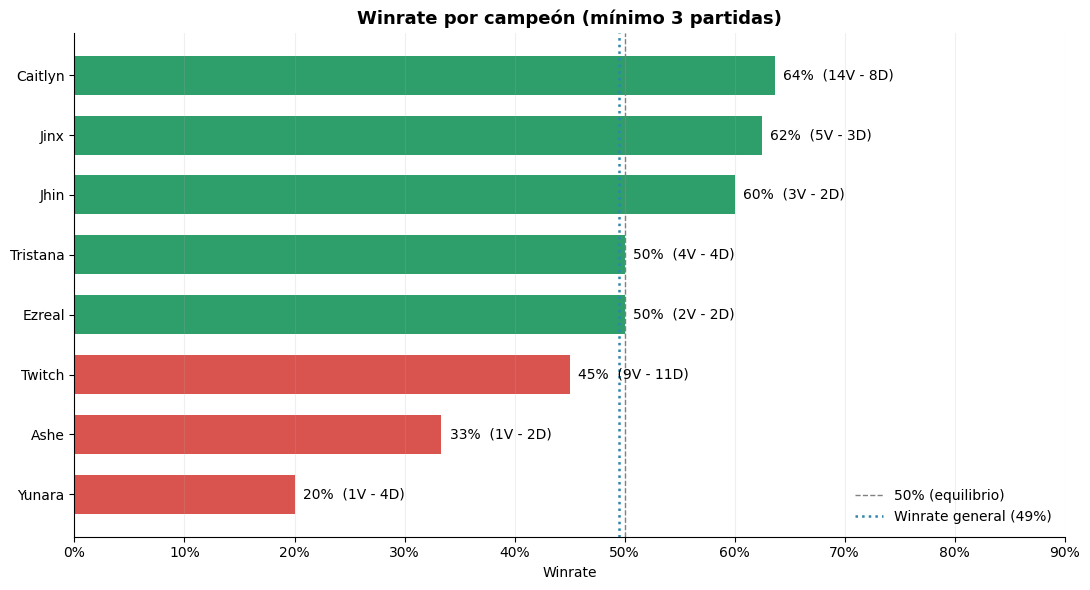

LECTURA (campeones con 10 o más partidas, los únicos con muestra razonable)
• Caitlyn: 64% en 22 partidas, 7.2 muertes y 6.4 CS/min por partida.
• Twitch: 45% en 20 partidas, 8.2 muertes y 5.3 CS/min por partida.


In [ ]:
# 10. ANÁLISIS POR CAMPEÓN

por_campeon = (partidas_validas.groupby("champion")
               .agg(partidas=("win", "size"), victorias=("win", "sum"), winrate=("win", "mean"),
                    kda=("kda", "mean"), muertes=("deaths", "mean"), cs_min=("cs_por_min", "mean"))
               .reset_index())
campeones = por_campeon[por_campeon["partidas"] >= MIN_PARTIDAS_CAMPEON].sort_values("winrate")
display(campeones.sort_values("partidas", ascending=False).round(2))

campeones = campeones.assign(derrotas=campeones["partidas"] - campeones["victorias"])
fig, eje = plt.subplots(figsize=(11, 6))
barras = eje.barh(campeones["champion"], campeones["winrate"] * 100,
                  color=np.where(campeones["winrate"] >= 0.5, VERDE, ROJO), height=0.65)
eje.bar_label(barras, labels=[f"{r.winrate:.0%}  ({int(r.victorias)}V - {int(r.derrotas)}D)" for r in campeones.itertuples()],
              padding=6, fontsize=10)
eje.axvline(50, color="gray", linestyle="--", linewidth=1, label="50% (equilibrio)")
eje.axvline(winrate_valido * 100, color=AZUL, linestyle=":", linewidth=1.8, label=f"Winrate general ({winrate_valido:.0%})")
eje.legend(loc="lower right", frameon=False)
eje.set_xlim(0, 90); eje.xaxis.set_major_formatter(PercentFormatter(100))
eje.set_xlabel("Winrate")
eje.set_title(f"Winrate por campeón (mínimo {MIN_PARTIDAS_CAMPEON} partidas)", fontsize=13, fontweight="bold")
eje.grid(axis="x", alpha=0.2); eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "05_campeones")
plt.show()

principales = por_campeon[por_campeon["partidas"] >= 10].sort_values("winrate", ascending=False)
print("LECTURA (campeones con 10 o más partidas, los únicos con muestra razonable)")
for r in principales.itertuples():
    print(f"• {r.champion}: {r.winrate:.0%} en {r.partidas} partidas, {r.muertes:.1f} muertes y {r.cs_min:.1f} CS/min por partida.")

## 11. Forma reciente
**Cómo leerla:** cada punto es una de las últimas 20 partidas (de la más antigua, 1, a la más reciente, 20). La línea es el **porcentaje de victorias en las últimas 5 partidas** en cada momento.

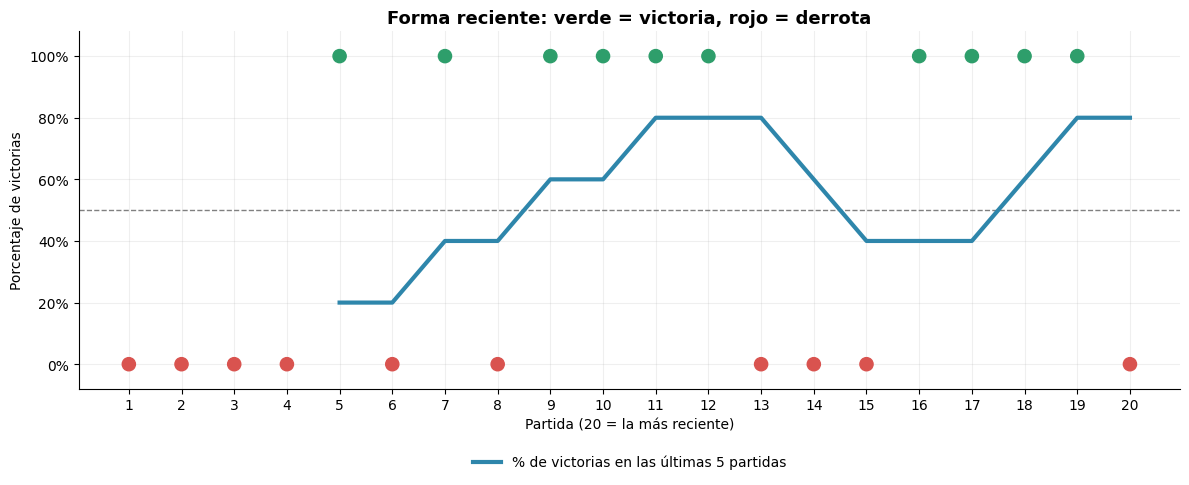

LECTURA
• Últimas 20 partidas: 10 victorias (50%).
• Últimas 10 partidas: 6 victorias (60%).
• Las últimas 20 partidas abarcan del 26/10 al 08/11.


In [ ]:
# 11. FORMA RECIENTE (últimas 20 partidas)

ultimas_20 = partidas_validas.tail(20).reset_index(drop=True)
numero = np.arange(1, len(ultimas_20) + 1)
gano = ultimas_20["win"].astype(int).values
media_movil = pd.Series(gano).rolling(5).mean() * 100

fig, eje = plt.subplots(figsize=(12, 5))
eje.axhline(50, color="gray", linestyle="--", linewidth=1)
eje.plot(numero, media_movil, color=AZUL, linewidth=3, label="% de victorias en las últimas 5 partidas")
eje.scatter(numero, gano * 100, s=90, c=np.where(gano == 1, VERDE, ROJO), zorder=3)
eje.set_ylim(-8, 108); eje.yaxis.set_major_formatter(PercentFormatter(100))
eje.set_xticks(numero)
eje.set_xlabel("Partida (20 = la más reciente)")
eje.set_ylabel("Porcentaje de victorias")
eje.set_title("Forma reciente: verde = victoria, rojo = derrota", fontsize=13, fontweight="bold")
eje.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15)); eje.grid(alpha=0.2); eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "06_forma_reciente")
plt.show()

ultimas_10 = partidas_validas.tail(10)
print("LECTURA")
print(f"• Últimas 20 partidas: {int(ultimas_20['win'].sum())} victorias ({ultimas_20['win'].mean():.0%}).")
print(f"• Últimas 10 partidas: {int(ultimas_10['win'].sum())} victorias ({ultimas_10['win'].mean():.0%}).")
print(f"• Las últimas 20 partidas abarcan del {ultimas_20['fecha'].min():%d/%m} al {ultimas_20['fecha'].max():%d/%m}.")

## 12. Cuándo juega
Riot guarda la hora en UTC, pero los datos ya vienen convertidos a la hora local de `ZONA_HORARIA` (por defecto Colombia, UTC−5). **Si el jugador vive en otra zona, las franjas se corren.**

**Cómo leerlo:** a la izquierda, cada casilla es un día y una hora, y su número son las partidas que empezó en ese momento. A la derecha, el winrate según la franja del día.

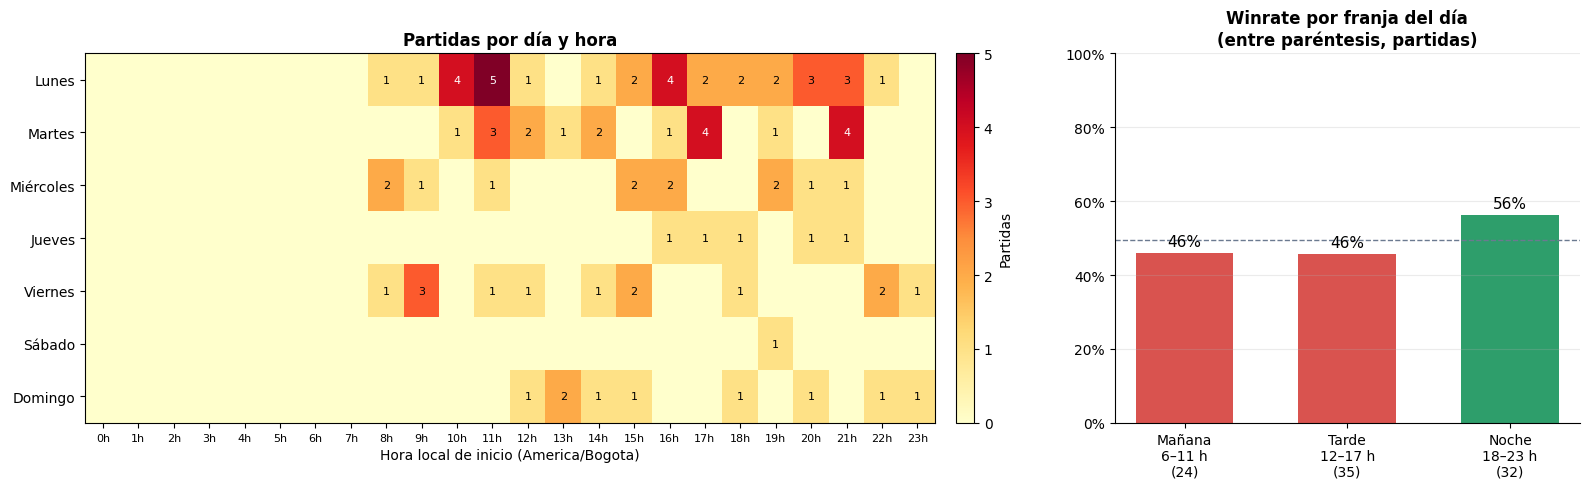

LECTURA
• Día con más partidas: Lunes (32). Hora más frecuente: 11:00.
• Mañana 6–11 h: 46% en 24 partidas.
• Tarde 12–17 h: 46% en 35 partidas.
• Noche 18–23 h: 56% en 32 partidas.
• Las franjas con menos de 10 partidas son solo una pista.


In [ ]:
# 12. DÍAS, HORAS Y WINRATE POR FRANJA

# Las fechas del CSV ya están en hora local (ZONA_HORARIA), así que NO se convierten otra vez
fechas = pd.to_datetime(partidas_validas["fecha"])
partidas_validas["hora_local"] = fechas.dt.hour
partidas_validas["dia_semana"] = fechas.dt.dayofweek

dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
tabla = (pd.crosstab(partidas_validas["dia_semana"], partidas_validas["hora_local"])
         .reindex(index=range(7), columns=range(24), fill_value=0))

partidas_validas["franja"] = pd.cut(partidas_validas["hora_local"], [-1, 5, 11, 17, 23],
                                    labels=["Madrugada\n0–5 h", "Mañana\n6–11 h", "Tarde\n12–17 h", "Noche\n18–23 h"])
wr_franja = partidas_validas.groupby("franja", observed=True)["win"].agg(["mean", "count"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
img = ax1.imshow(tabla.values, cmap="YlOrRd", aspect="auto")
for i in range(7):
    for j in range(24):
        if tabla.iloc[i, j] > 0:
            ax1.text(j, i, tabla.iloc[i, j], ha="center", va="center", fontsize=8,
                     color="white" if tabla.iloc[i, j] > tabla.values.max() * 0.6 else "black")
ax1.set_xticks(range(24)); ax1.set_xticklabels([f"{h}h" for h in range(24)], fontsize=8)
ax1.set_yticks(range(7)); ax1.set_yticklabels(dias)
ax1.set_xlabel(f"Hora local de inicio ({ZONA_HORARIA})")
ax1.set_title("Partidas por día y hora", fontweight="bold")
fig.colorbar(img, ax=ax1, pad=0.02).set_label("Partidas")

barras = ax2.bar([f"{i}\n({int(n)})" for i, n in zip(wr_franja.index, wr_franja["count"])],
                 wr_franja["mean"] * 100, color=[VERDE if v >= 0.5 else ROJO for v in wr_franja["mean"]], width=0.6)
ax2.bar_label(barras, labels=[f"{v:.0%}" for v in wr_franja["mean"]], padding=3, fontsize=11)
ax2.axhline(winrate_valido * 100, color=GRIS, linestyle="--", linewidth=1)
ax2.set_ylim(0, 100); ax2.yaxis.set_major_formatter(PercentFormatter(100))
ax2.set_title("Winrate por franja del día\n(entre paréntesis, partidas)", fontweight="bold")
ax2.grid(axis="y", alpha=0.25); ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "07_horarios")
plt.show()

print("LECTURA")
print(f"• Día con más partidas: {dias[tabla.sum(axis=1).idxmax()]} ({tabla.sum(axis=1).max()}). "
      f"Hora más frecuente: {tabla.sum(axis=0).idxmax()}:00.")
for franja, r in wr_franja.iterrows():
    print(f"• {franja.replace(chr(10), ' ')}: {r['mean']:.0%} en {int(r['count'])} partidas.")
print("• Las franjas con menos de 10 partidas son solo una pista.")

## 13. Correlación con el resultado
Mide qué tan de la mano va cada estadística con ganar (de −1 a +1). **Verde** = cuando sube, tiende a haber victoria; **rojo** = cuando sube, tiende a haber derrota. La zona gris (±0.2) es una relación débil que con ~90 partidas podría ser casualidad.

**Ojo con las muertes:** la barra roja son las *muertes del jugador*, no las kills. Morir más va con perder más.

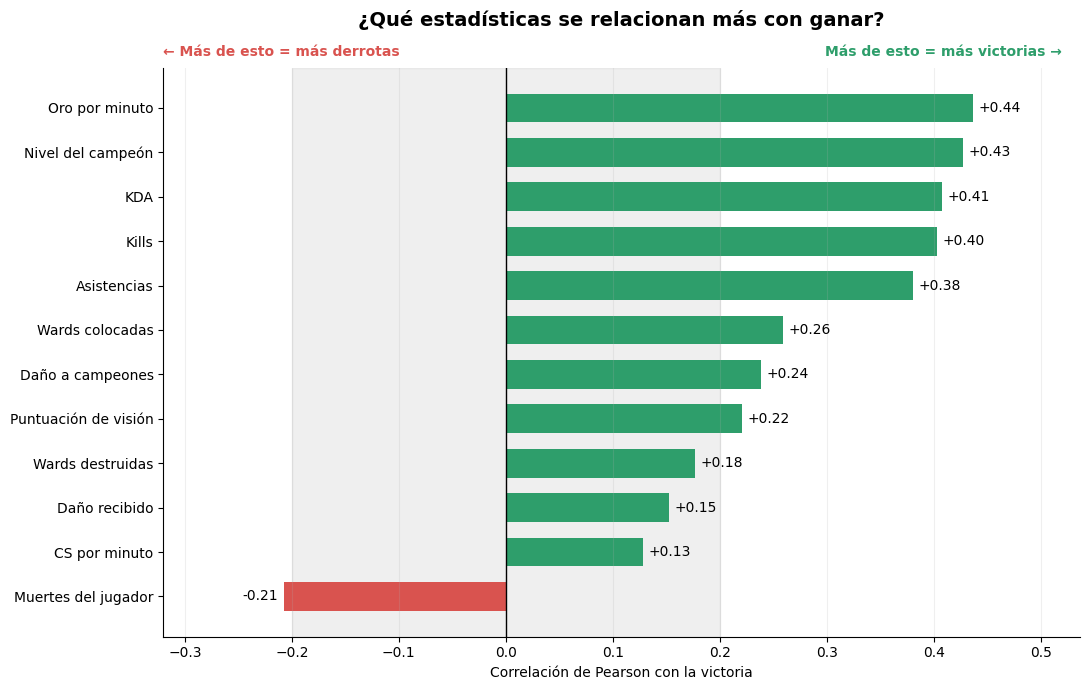

Nota: correlación no significa causalidad (el oro y el nivel dependen de si el equipo va ganando).


In [ ]:
# 13. CORRELACIÓN CON LA VICTORIA

nombres = {"kills": "Kills", "deaths": "Muertes del jugador", "assists": "Asistencias", "kda": "KDA",
           "cs_por_min": "CS por minuto", "gold_por_min": "Oro por minuto", "damage_dealt": "Daño a campeones",
           "damage_taken": "Daño recibido", "vision_score": "Puntuación de visión", "wards_placed": "Wards colocadas",
           "wards_killed": "Wards destruidas", "champ_level": "Nivel del campeón"}

correlaciones = (partidas_validas[list(nombres)].corrwith(partidas_validas["win"].astype(int)).sort_values())

fig, eje = plt.subplots(figsize=(11, 7))
barras = eje.barh([nombres[v] for v in correlaciones.index], correlaciones.values,
                  color=[VERDE if v > 0 else ROJO for v in correlaciones.values], height=0.65)
eje.bar_label(barras, fmt="%+.2f", padding=4, fontsize=10)
eje.axvspan(-0.2, 0.2, color="gray", alpha=0.12, zorder=0)
eje.axvline(0, color="black", linewidth=1)
eje.text(0.0, 1.02, "← Más de esto = más derrotas", transform=eje.transAxes, ha="left", color=ROJO, fontsize=10, fontweight="bold")
eje.text(0.98, 1.02, "Más de esto = más victorias →", transform=eje.transAxes, ha="right", color=VERDE, fontsize=10, fontweight="bold")
eje.set_xlim(min(correlaciones.min() - 0.1, -0.32), correlaciones.max() + 0.1)
eje.set_title("¿Qué estadísticas se relacionan más con ganar?", fontsize=14, fontweight="bold", pad=30)
eje.set_xlabel("Correlación de Pearson con la victoria")
eje.grid(axis="x", alpha=0.2); eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_fig(fig, "08_correlaciones")
plt.show()
print("Nota: correlación no significa causalidad (el oro y el nivel dependen de si el equipo va ganando).")

## 14. Mapas de calor: dónde juega, mata y muere
El mapa se ve desde arriba: la **base azul** está abajo a la izquierda y la **roja** arriba a la derecha. Cuanto más intenso el color, más veces pasó ahí. Los hexágonos pálidos son pocos eventos; fíjate en las zonas oscuras.

Se quitan el minuto 0 y las bases porque ahí solo está apareciendo o volviendo a comprar.

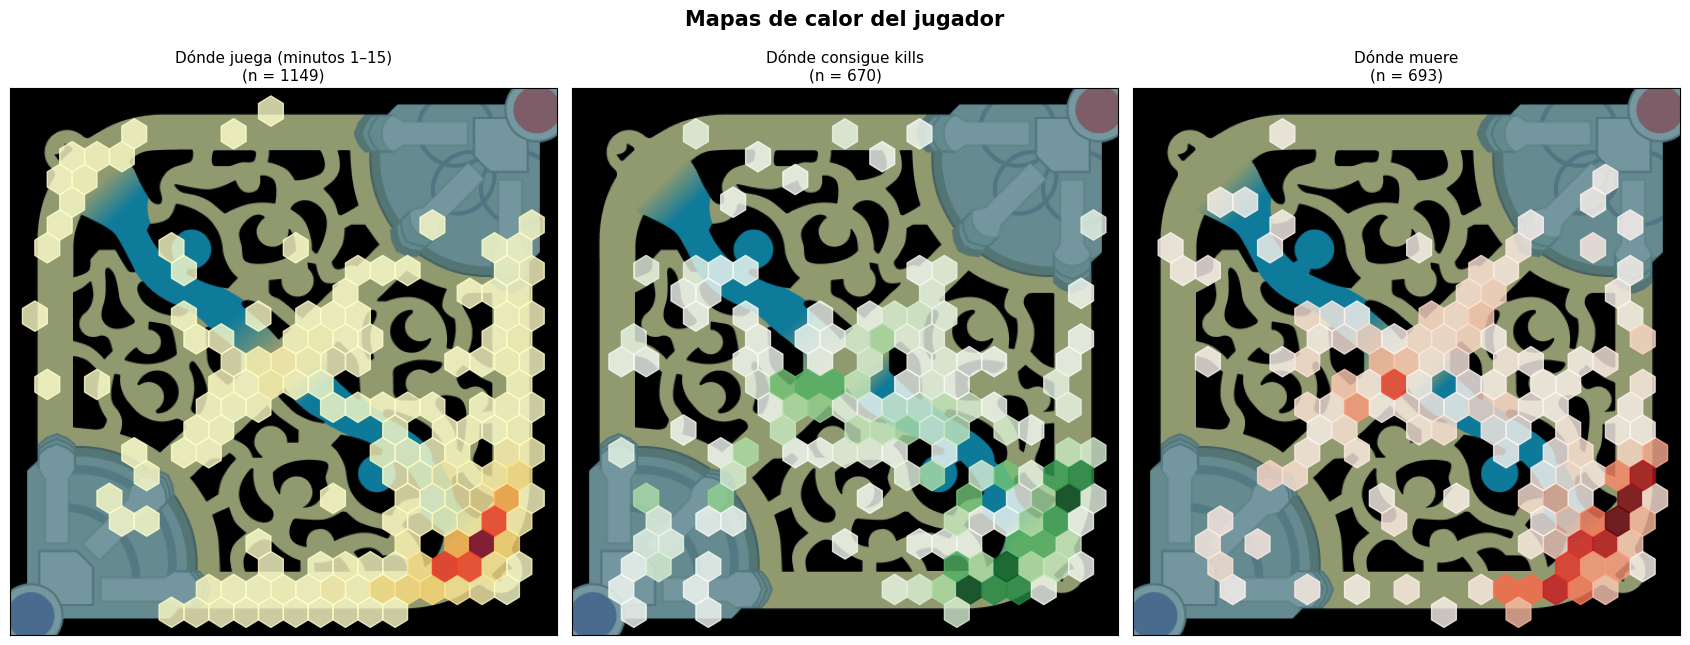

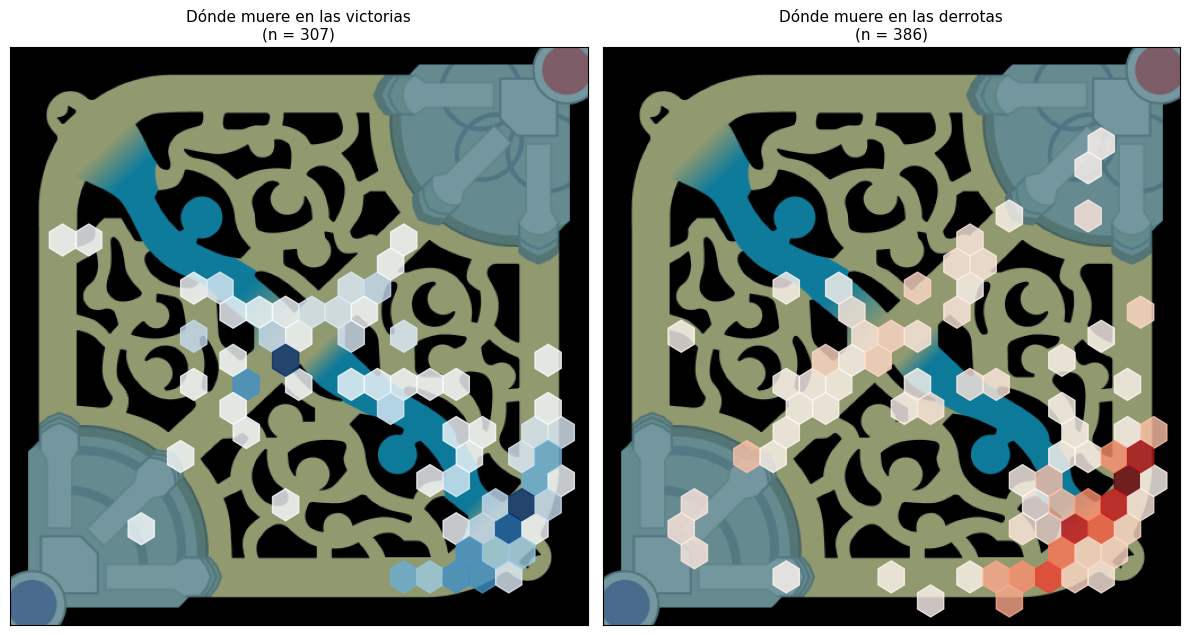

LECTURA
• Mira dónde está la mancha más oscura de cada panel: ahí se concentran sus peleas.
• Si mata y muere en la misma zona, esa zona es donde se decide su partida.


In [ ]:
# 14. MAPAS DE CALOR

LIMITE_MAPA = 14870

def cargar_fondo_mapa():
    """Descarga la imagen del mapa desde Riot; si falla, se dibuja sin fondo."""
    try:
        version = requests.get("https://ddragon.leagueoflegends.com/api/versions.json", timeout=10).json()[0]
        r = requests.get(f"https://ddragon.leagueoflegends.com/cdn/{version}/img/map/map11.png", timeout=10)
        r.raise_for_status()
        return mpimg.imread(io.BytesIO(r.content), format="png")
    except Exception as e:
        print("No se pudo cargar el fondo del mapa (el calor se dibuja sin fondo):", e)
        return None

fondo = cargar_fondo_mapa()

def dibujar_calor(eje, x, y, titulo, cmap, minimo=1):
    if fondo is not None:
        eje.imshow(fondo, extent=[0, LIMITE_MAPA, 0, LIMITE_MAPA], zorder=0)
    if len(x) > 0:
        eje.hexbin(x, y, gridsize=22, extent=(0, LIMITE_MAPA, 0, LIMITE_MAPA), cmap=cmap, mincnt=minimo, alpha=0.8, zorder=1)
    eje.set_xlim(0, LIMITE_MAPA); eje.set_ylim(0, LIMITE_MAPA)
    eje.set_aspect("equal"); eje.set_xticks([]); eje.set_yticks([])
    eje.set_title(f"{titulo}\n(n = {len(x)})", fontsize=11)

def lejos_de_bases(df, radio=3000):
    d_azul = np.hypot(df["x"] - 500, df["y"] - 500)
    d_rojo = np.hypot(df["x"] - 14300, df["y"] - 14300)
    return df[(d_azul > radio) & (d_rojo > radio)]

mis_frames = frames[frames["es_mi_jugador"]].dropna(subset=["x", "y"])
juego = lejos_de_bases(mis_frames[(mis_frames["minuto"] >= 1) & (mis_frames["minuto"] <= 15)])

ev = kills_ev.dropna(subset=["x", "y"]).merge(partidas_validas[["match_id", "resultado"]], on="match_id")
mis_kills = ev[ev["killer_id"] == ev["mi_id"]]
mis_muertes_mapa = ev[ev["victim_id"] == ev["mi_id"]]

fig, ejes = plt.subplots(1, 3, figsize=(17, 6.5))
dibujar_calor(ejes[0], juego["x"], juego["y"], "Dónde juega (minutos 1–15)", "YlOrRd")
dibujar_calor(ejes[1], mis_kills["x"], mis_kills["y"], "Dónde consigue kills", "Greens", minimo=2)
dibujar_calor(ejes[2], mis_muertes_mapa["x"], mis_muertes_mapa["y"], "Dónde muere", "Reds", minimo=2)
fig.suptitle("Mapas de calor del jugador", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.95])
guardar_fig(fig, "09_mapas_calor")
plt.show()

# Muertes en victorias vs. derrotas
fig, ejes = plt.subplots(1, 2, figsize=(12, 6.5))
for eje, res, cmap in zip(ejes, ["Victoria", "Derrota"], ["Blues", "Reds"]):
    s = mis_muertes_mapa[mis_muertes_mapa["resultado"] == res]
    dibujar_calor(eje, s["x"], s["y"], f"Dónde muere en las {res.lower()}s", cmap, minimo=2)
plt.tight_layout()
guardar_fig(fig, "10_muertes_victoria_vs_derrota")
plt.show()

print("LECTURA")
print("• Mira dónde está la mancha más oscura de cada panel: ahí se concentran sus peleas.")
print("• Si mata y muere en la misma zona, esa zona es donde se decide su partida.")

## 15. Diagnóstico: qué mantener, qué corregir y qué probar
Esta sección **se escribe sola** con los números de los datos: si cambias los CSV, el diagnóstico se actualiza. Es el resumen que se lleva a las diapositivas.

In [ ]:
# 15. DIAGNÓSTICO AUTOMÁTICO

v = partidas_validas
lineas = []

def agregar(texto=""):
    lineas.append(texto)
    print(texto)

# --- Datos de apoyo ---
mejor = principales.iloc[0] if len(principales) else None
peor = principales.iloc[-1] if len(principales) > 1 else None
v15_adelante = v15[v15["dif_oro"] > 0]["win"].mean()
v15_atras = v15[v15["dif_oro"] <= 0]["win"].mean()
dur_larga = wr_duracion.iloc[2]["mean"]
dur_corta = wr_duracion.iloc[0]["mean"]
franjas_ok = wr_franja[wr_franja["count"] >= 10]

agregar("=" * 60)
agregar(f"DIAGNÓSTICO · {GAME_NAME}#{TAG_LINE} · {len(v)} partidas válidas · winrate {winrate_valido:.0%}")
agregar("=" * 60)

agregar("\nQUÉ MANTENER")
if mejor is not None:
    agregar(f"• {mejor['champion']} es su campeón más sólido: {mejor['winrate']:.0%} en {int(mejor['partidas'])} partidas.")
agregar(f"• Participa en las peleas: {v.loc[v['win'], 'kills'].mean():.1f} kills al ganar frente a {v.loc[~v['win'], 'kills'].mean():.1f} al perder.")
agregar(f"• Cierra bien las partidas largas: {dur_larga:.0%} de winrate entre 32 y 40 minutos.")
agregar(f"• Cuando llega al minuto 15 por delante en oro, gana el {v15_adelante:.0%}.")

agregar("\nEN QUÉ FALLA")
agregar(f"• Muere mucho: {v['deaths'].mean():.1f} muertes por partida, sobre todo en {fase_pico}.")
agregar(f"• Con 9 o más muertes gana el {wr_muertes.loc['9+ muertes','mean']:.0%}; con 5 o menos, el {wr_muertes.loc['0–5 muertes','mean']:.0%}.")
agregar(f"• Pierde las partidas cortas: gana solo el {dur_corta:.0%} cuando duran menos de 25 minutos.")
agregar(f"• Va por detrás en oro al minuto 15 y entonces gana solo el {v15_atras:.0%}: el arranque de la partida es el problema.")
if peor is not None:
    agregar(f"• {peor['champion']} es donde peor le va entre los más jugados: {peor['winrate']:.0%} en {int(peor['partidas'])} partidas.")

agregar("\nQUÉ PROBAR")
agregar(f"• Bajar de {v['deaths'].mean():.1f} a 5–6 muertes por partida, cuidando especialmente {fase_pico}.")
agregar("• Llegar al minuto 15 igual o por delante en oro: más CS y trades seguros en la fase de líneas.")
agregar("• No forzar peleas cuando va por detrás en oro; jugar para escalar hacia las partidas largas, donde rinde mejor.")
if len(franjas_ok) > 1:
    mejor_f, peor_f = franjas_ok["mean"].idxmax(), franjas_ok["mean"].idxmin()
    agregar(f"• Comparar horarios: {mejor_f.replace(chr(10), ' ')} ({franjas_ok['mean'].max():.0%}) frente a {peor_f.replace(chr(10), ' ')} ({franjas_ok['mean'].min():.0%}).")
if peor is not None:
    agregar(f"• Revisar repeticiones de {peor['champion']} para ver por qué muere tanto y farmea poco.")

agregar("\nCOMPLEMENTO")
agregar("• Con ~90 partidas estos son patrones para probar, no verdades. Revisa los mismos números en 30–40 partidas nuevas.")

with open("graficos/diagnostico.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lineas))

DIAGNÓSTICO · KBTZASK8#9829 · 91 partidas válidas · winrate 49%

QUÉ MANTENER
• Caitlyn es su campeón más sólido: 64% en 22 partidas.
• Participa en las peleas: 9.4 kills al ganar frente a 5.4 al perder.
• Cierra bien las partidas largas: 63% de winrate entre 32 y 40 minutos.
• Cuando llega al minuto 15 por delante en oro, gana el 64%.

EN QUÉ FALLA
• Muere mucho: 7.7 muertes por partida, sobre todo en Min 10–20.
• Con 9 o más muertes gana el 41%; con 5 o menos, el 60%.
• Pierde las partidas cortas: gana solo el 35% cuando duran menos de 25 minutos.
• Va por detrás en oro al minuto 15 y entonces gana solo el 38%: el arranque de la partida es el problema.
• Twitch es donde peor le va entre los más jugados: 45% en 20 partidas.

QUÉ PROBAR
• Bajar de 7.7 a 5–6 muertes por partida, cuidando especialmente Min 10–20.
• Llegar al minuto 15 igual o por delante en oro: más CS y trades seguros en la fase de líneas.
• No forzar peleas cuando va por detrás en oro; jugar para escalar hacia las part

## 16. Exportar para las diapositivas
Se descargan todas las gráficas (imágenes en alta calidad) y el diagnóstico en un solo `.zip`.

In [ ]:
# 16. EXPORTAR GRÁFICAS Y DIAGNÓSTICO

import shutil
shutil.make_archive("graficos_analisis", "zip", "graficos")
print("Archivos exportados:")
for nombre in sorted(os.listdir("graficos")):
    print("  •", nombre)

if EN_COLAB:
    files.download("graficos_analisis.zip")

Archivos exportados:
  • 01_victoria_vs_derrota.png
  • 02_muertes.png
  • 03_oro_vs_rivales.png
  • 04_duracion.png
  • 05_campeones.png
  • 06_forma_reciente.png
  • 07_horarios.png
  • 08_correlaciones.png
  • 09_mapas_calor.png
  • 10_muertes_victoria_vs_derrota.png
  • diagnostico.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>